# 04 — Avaliação: Hit Rate e Serendipity

Duas perguntas:

- **Hit Rate:** o modelo recomenda algo de que o usuário realmente gosta?
- **Serendipity:** o modelo recomenda algo além dos animes que todo mundo já conhece?

Comparamos as três distâncias da filtragem colaborativa com dois baselines:
recomendar simplesmente os animes mais populares, e o modelo baseado em itens do notebook anterior.

In [1]:
import numpy as np
import pandas as pd

from joblib import load

from src.config import (
    ANIMES_CLUSTERS,
    MATRIZ_USUARIO_ANIME,
    MAX_PERSONAS,
    METRICAS,
    METRICAS_DISTANCIA,
    RANDOM_STATE,
)
from src.graficos import ROTULOS, barras_horizontais, configurar_estilo
from src.models import (
    ajustar_vizinhos,
    combinacoes_de_personas,
    hit_rate,
    montar_vetores,
    recomendar_populares,
    recomendar_por_itens,
    recomendar_por_usuarios,
    separar_anime_nota_maxima,
    serendipity,
    similaridade_entre_animes,
)

configurar_estilo()

animes = pd.read_parquet(ANIMES_CLUSTERS)
matriz = load(MATRIZ_USUARIO_ANIME)

## 1. Hit Rate

Para cada usuário de teste:

1. pegamos os animes que ele avaliou com nota 10 e **escondemos um**;
2. rodamos o modelo com o restante das notas dele;
3. conta como *hit* se o anime escondido aparece entre as 10 recomendações.

$$\text{Hit Rate} = \frac{\text{Nº de usuários hit}}{\text{Nº total de usuários}}$$

Os 2.000 usuários de teste ficam fora da base em que o modelo busca vizinhos, para ninguém ser vizinho de si mesmo.

In [2]:
N_TESTE = 2_000

rng = np.random.default_rng(RANDOM_STATE)
tem_nota_10 = np.flatnonzero((matriz == 10).getnnz(axis=1) > 0)
teste = rng.choice(tem_nota_10, N_TESTE, replace=False)
treino = np.setdiff1d(np.arange(matriz.shape[0]), teste)

matriz_treino = matriz[treino]
vetores_teste, alvos = separar_anime_nota_maxima(matriz[teste], RANDOM_STATE)

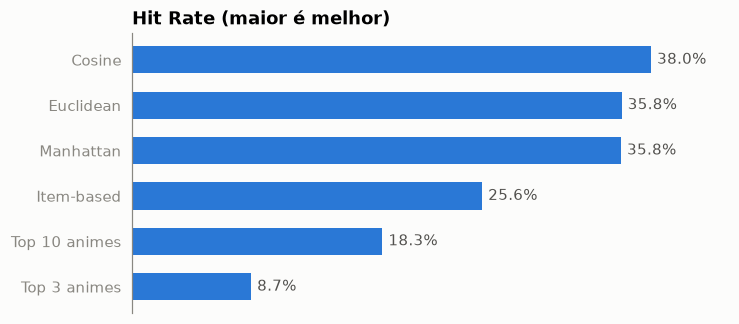

In [3]:
similaridade_treino = similaridade_entre_animes(matriz_treino)

recomendacoes = {
    metrica: recomendar_por_usuarios(ajustar_vizinhos(matriz_treino, metrica), matriz_treino, vetores_teste)
    for metrica in METRICAS_DISTANCIA
}
recomendacoes["item"] = recomendar_por_itens(similaridade_treino, vetores_teste)
recomendacoes["top10"] = recomendar_populares(matriz_treino, vetores_teste, n=10)
recomendacoes["top3"] = recomendar_populares(matriz_treino, vetores_teste, n=3)

hit_rates = pd.Series({ROTULOS[nome]: hit_rate(r, alvos) for nome, r in recomendacoes.items()}, name="Hit Rate")
barras_horizontais(hit_rates, "Hit Rate (maior é melhor)", formato="{:.1%}", arquivo="hit_rate.png");

Os baselines "Top 10" e "Top 3" recomendam os animes mais avaliados **que o usuário ainda não viu**.
É um baseline mais forte do que uma lista fixa igual para todos, o que deixa a comparação mais justa.

Com 2.000 usuários, a margem de erro de cada barra é de cerca de ±2 pontos percentuais.

- As três distâncias ficam bem acima de recomendar os mais populares (18,3% no Top 10): **o modelo aprende gosto, não só popularidade**. Esse é o mesmo resultado central da monografia.
- **Cosseno** tem o melhor Hit Rate (38,0%), como na monografia. Manhattan e Euclidiana empatam (35,8%), cerca de 2 pontos abaixo, uma diferença pequena, do tamanho da margem de erro.
- O modelo baseado em itens (25,6%) fica abaixo da filtragem por usuários, então não substitui o método original.

## 2. Serendipity

Aqui o cenário é o do app: usuário novo que escolhe de 1 a 3 personas.
Geramos as recomendações para **todas** as combinações possíveis (1.350) e medimos quantas delas caem no Top 10 de animes mais populares:

$$\text{Serendipity} = \frac{\text{Nº de aparições de animes do Top 10}}{\text{Nº total de recomendações}}$$

Quanto **menor**, mais o modelo foge do óbvio.

In [4]:
personas = animes.index[animes["Persona"]].tolist()
combinacoes = combinacoes_de_personas(personas, MAX_PERSONAS)
vetores_personas = montar_vetores(combinacoes, n_animes=matriz.shape[1])
print(f"{len(combinacoes)} combinações de personas")

top10 = np.argsort(-matriz.getnnz(axis=0), kind="stable")[:10]
animes.loc[top10, ["Name", "Avaliações na amostra", "Persona"]]

1350 combinações de personas


,Name,Avaliações na amostra,Persona
1174,Death Note,13967,True
3640,Shingeki no Kyojin,13571,False
3218,Sword Art Online,12825,True
2458,Angel Beats!,11473,True
4499,One Punch Man,11423,False
1203,Code Geass: Hangyaku no Lelouch,11231,True
2095,Toradora!,11164,False
3879,No Game No Life,10774,True
2234,Fullmetal Alchemist: Brotherhood,10729,True
4071,Tokyo Ghoul,10505,False


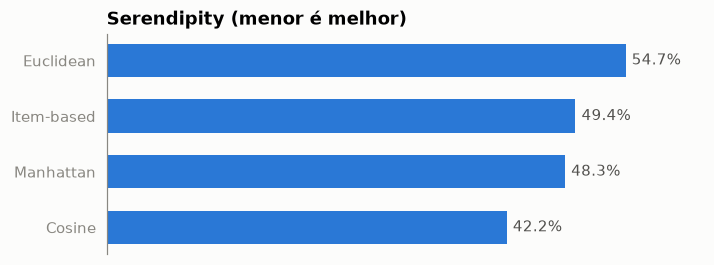

In [5]:
recomendacoes_personas = {
    metrica: recomendar_por_usuarios(ajustar_vizinhos(matriz, metrica), matriz, vetores_personas)
    for metrica in METRICAS_DISTANCIA
}
recomendacoes_personas["item"] = recomendar_por_itens(similaridade_entre_animes(matriz), vetores_personas)

serendipities = pd.Series(
    {ROTULOS[nome]: serendipity(r, top10) for nome, r in recomendacoes_personas.items()}, name="Serendipity"
)
barras_horizontais(serendipities, "Serendipity (menor é melhor)", formato="{:.1%}", arquivo="serendipity.png");

Outra forma de ver a diversidade: quantos animes **diferentes** cada modelo chega a recomendar somando as 1.350 combinações.

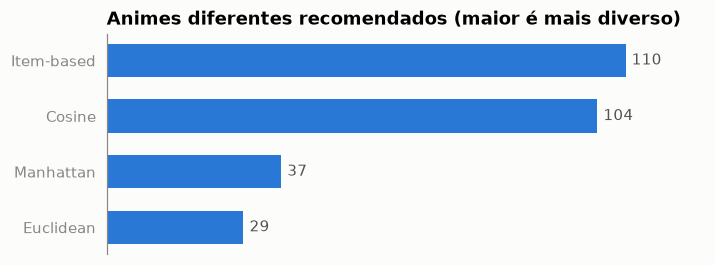

In [6]:
diversidade = pd.Series(
    {ROTULOS[nome]: len(np.unique(r)) for nome, r in recomendacoes_personas.items()}, name="Animes diferentes recomendados"
)
barras_horizontais(diversidade, "Animes diferentes recomendados (maior é mais diverso)", arquivo="diversidade.png");

- **Cosseno** é a distância que menos repete o Top 10 (42,2%) e a que recomenda mais animes diferentes (104).
- **Manhattan** (48,3%, 37 animes) e **Euclidiana** (54,7%, 29 animes) giram em torno de um conjunto pequeno de títulos famosos.
  É o efeito visto no notebook 03: com um usuário novo, elas escolhem como vizinhos os usuários com menos avaliações, que assistiram principalmente os animes mais conhecidos.

Mesmo no melhor caso, 4 em cada 10 recomendações são do Top 10. Parte disso é esperado: as personas são os animes mais populares de cada cluster, então quem gosta delas tende a gostar dos outros sucessos.

## 3. Resumo

In [7]:
resumo = pd.concat([hit_rates, serendipities, diversidade], axis=1)
resumo.to_csv(METRICAS, index_label="Modelo")
resumo.style.format({"Hit Rate": "{:.1%}", "Serendipity": "{:.1%}", "Animes diferentes recomendados": "{:.0f}"}, na_rep="—")

,Hit Rate,Serendipity,Animes diferentes recomendados
Cosine,38.0%,42.2%,104
Manhattan,35.8%,48.3%,37
Euclidean,35.8%,54.7%,29
Item-based,25.6%,49.4%,110
Top 10 animes,18.3%,—,—
Top 3 animes,8.7%,—,—


## Conclusão

Nesta reprodução, a distância **Cosseno** é a melhor nas duas métricas: maior Hit Rate e menor Serendipity (mais novidade). É a distância usada como padrão no app.

**Diferença em relação à monografia:** lá, o Cosseno também teve o melhor Hit Rate, mas a Manhattan teve a menor Serendipity e foi a escolhida.
Aqui a Manhattan não repetiu esse resultado. O código original se perdeu, então não dá para apontar a causa com certeza; os candidatos são
a base (API do MyAnimeList na época, Kaggle 2020 agora), a amostra de usuários e a regra usada para transformar vizinhos em recomendações.

O que se mantém:

- a filtragem colaborativa por usuários recomenda bem melhor do que simplesmente indicar os animes mais populares;
- a escolha da distância muda bastante a diversidade das recomendações, então vale medir novidade além de acerto.